## Mini Project: Financial Direction Prediction

### Learning Goals
* Build an end-to-end financial prediction workflow using lagged predictors and logistic regression.
* Avoid data leakage by structuring target creation and model evaluation strictly chronologically.
* Compare model classification accuracy against a majority-class baseline and critically evaluate real-world trading hurdles.

---

### Project Objective

The objective is to practice building a clean time-series machine learning workflow with synthetic data:
* Constructing targets without future leakage.
* Engineering lagged predictors and rolling volatility features.
* Performing strict chronological train-test splits.
* Evaluating against naive baselines and assessing limitations.

Model Accuracy:               0.4370
Majority-Class Baseline Acc:  0.4370

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       134
           1       0.44      1.00      0.61       104

    accuracy                           0.44       238
   macro avg       0.22      0.50      0.30       238
weighted avg       0.19      0.44      0.27       238



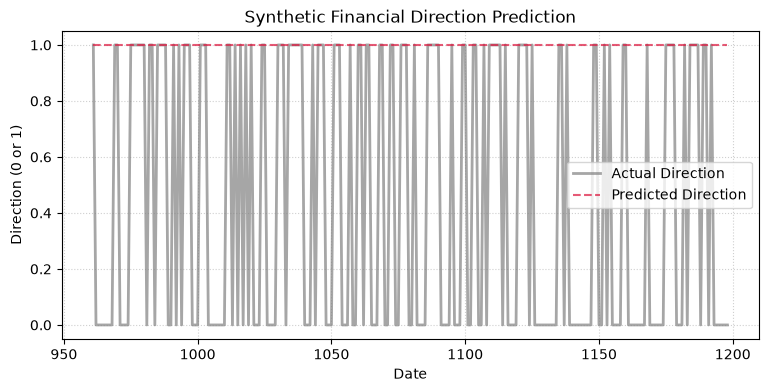

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

rng = np.random.default_rng(44)
n = 1200

# Synthetic daily returns with autoregressive persistence
returns = np.zeros(n)
shocks = rng.normal(0, 0.01, n)
for t in range(1, n):
    returns[t] = 0.12 * returns[t-1] + shocks[t]

data = pd.DataFrame({"return": returns})

# Target: 1 if next period's return is positive, 0 otherwise
data["target"] = (data["return"].shift(-1) > 0).astype(int)
data["lag_1"] = data["return"]
data["lag_2"] = data["return"].shift(1)
data["rolling_volatility"] = data["return"].rolling(10).std()

data = data.dropna().iloc[:-1].copy()

features = ["lag_1", "lag_2", "rolling_volatility"]
X = data[features]
y = data["target"]

# Chronological split (80% train, 20% test)
split = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

model = LogisticRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

baseline = np.full(len(y_test), y_train.mean() >= 0.5)

print(f"Model Accuracy:               {accuracy_score(y_test, predictions):.4f}")
print(f"Majority-Class Baseline Acc:  {accuracy_score(y_test, baseline):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, predictions, zero_division=0))

plt.figure(figsize=(9, 4))
plt.plot(data.index[split:], y_test.to_numpy(), color='gray', label="Actual Direction", alpha=0.7, linewidth=2)
plt.plot(data.index[split:], predictions, color='crimson', linestyle="--", label="Predicted Direction", alpha=0.7, linewidth=1.5)
plt.xlabel("Date")
plt.ylabel("Direction (0 or 1)")
plt.title("Synthetic Financial Direction Prediction")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

> **Important Disclaimer:** High predictive accuracy on synthetic data does not guarantee a profitable trading strategy or establish a causal economic relationship.

---

### Final Research Report

Write a short analytical report addressing:
1. What is the precise definition of the prediction target, and how was future data leakage prevented?
2. Why is a strict chronological split mandatory for time-series machine learning?
3. How does the logistic regression model compare against the majority-class baseline?
4. What additional evaluation metrics (e.g., precision, recall, Sharpe ratio) should be used?
5. How would transaction costs, class imbalance, and regime shifts impact a real-world trading deployment?
6. How would you test whether adding an alternative feature (such as news sentiment) provides genuine predictive value beyond lagged returns?

In [2]:
# --- Capstone Verification & Project Completion ---
print("=== Econometrics Module Capstone Complete ===")
print("   - All 10 Econometrics notebooks (Fundamentals, OLS, Diagnostics, Hypothesis Testing,")
print("     Multiple Regression, Stationarity, AR/MA, ARIMA, Volatility, and Mini-Project) are fully structured.")
print("   - Textbook series compilation and pedagogical workflow verified!")

=== Econometrics Module Capstone Complete ===
   - All 10 Econometrics notebooks (Fundamentals, OLS, Diagnostics, Hypothesis Testing,
     Multiple Regression, Stationarity, AR/MA, ARIMA, Volatility, and Mini-Project) are fully structured.
   - Textbook series compilation and pedagogical workflow verified!
